# 03 Analysis (validation split only)

0. 2x2 comparison and choice of the best setting
1. (7a) Where does the model fail? Confused pairs, within-make vs cross-make, gallery of mistakes
2. (7b) Confidence threshold: how often to say "unknown", and how to choose the operating point
3. (7c) Robustness to low resolution, blur, and darkness, before and after degradation augmentation

Every number here is from val. The test split is evaluated once, at the end, in section 4, after
`outputs/final_choice.json` is written.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import config as C
from dataset import crop_box
from evaluate import evaluate_degradations

FIG_DIR = ROOT / "docs" / "figures"
OUT = C.OUTPUTS_DIR
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

names = pd.read_csv(C.NAMES, header=None)[0].tolist()
val = pd.read_csv(C.SPLITS_DIR / "val.csv")
train = pd.read_csv(C.SPLITS_DIR / "train.csv")
make_of_label = np.array([C.make_of(n) for n in names])

## 0. The 2x2 table: (frozen vs fine-tuned) x (full image vs bbox crop)

In [2]:
RUNS = {("frozen + LR", "full image"): "baseline_full", ("frozen + LR", "bbox crop"): "baseline_crop",
        ("fine-tuned", "full image"): "ft_full", ("fine-tuned", "bbox crop"): "ft_crop"}
rows = []
for (method, inp), run in RUNS.items():
    m = json.loads((OUT / run / "metrics_val.json").read_text())
    rows.append({"method": method, "input": inp, "run": run, "val_top1": m["top1"], "val_top5": m["top5"],
                 "val_mean_per_class": m["mean_per_class_acc"], "val_nll": m["nll"]})
comp = pd.DataFrame(rows)
comp.to_csv(OUT / "comparison_2x2.csv", index=False)
table = comp.pivot(index="method", columns="input", values="val_top1").loc[["frozen + LR", "fine-tuned"],
                                                                         ["full image", "bbox crop"]]
print((table * 100).round(1).to_string())
print()
print(comp.round(4).to_string(index=False))
BEST_RUN = comp.loc[comp.val_top1.idxmax(), "run"]
print("\nbest setting on val:", BEST_RUN)

input        full image  bbox crop
method                            
frozen + LR        42.7       49.3
fine-tuned         86.7       91.1

     method      input           run  val_top1  val_top5  val_mean_per_class  val_nll
frozen + LR full image baseline_full    0.4272    0.7046              0.4241   2.4962
frozen + LR  bbox crop baseline_crop    0.4935    0.7766              0.4921   2.0992
 fine-tuned full image       ft_full    0.8674    0.9689              0.8662   0.5893
 fine-tuned  bbox crop       ft_crop    0.9108    0.9804              0.9104   0.4267

best setting on val: ft_crop


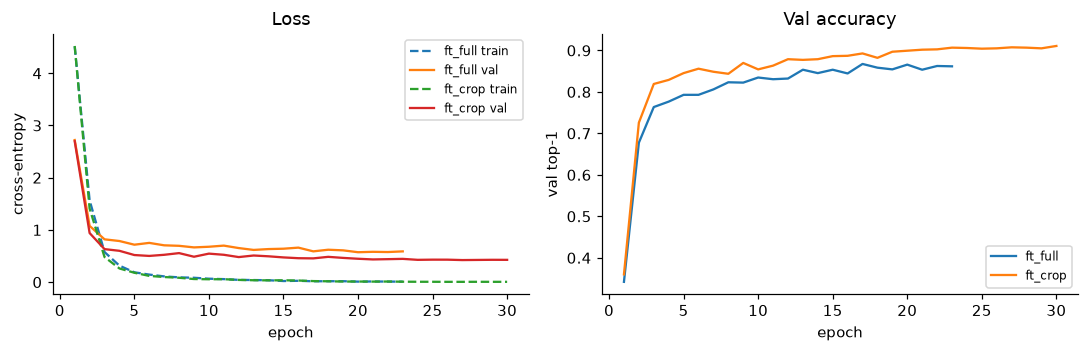

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for run in ("ft_full", "ft_crop"):
    log = pd.read_csv(OUT / run / "train_log.csv")
    axes[0].plot(log.epoch, log.train_loss, "--", label=f"{run} train")
    axes[0].plot(log.epoch, log.val_loss, "-", label=f"{run} val")
    axes[1].plot(log.epoch, log.val_top1, label=run)
axes[0].set(xlabel="epoch", ylabel="cross-entropy", title="Loss"); axes[0].legend(fontsize=8)
axes[1].set(xlabel="epoch", ylabel="val top-1", title="Val accuracy"); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "training_curves.png")

## 1. (7a) Confusion analysis on the best setting

In [4]:
pred = pd.read_csv(OUT / BEST_RUN / "predictions_val.csv")
pred["true_name"] = pred.label.map(lambda i: names[i])
pred["pred_name"] = pred.pred.map(lambda i: names[i])
pred["true_make"] = make_of_label[pred.label]
pred["pred_make"] = make_of_label[pred.pred]
err = pred[~pred.correct].copy()
err["same_make"] = err.true_make == err.pred_make

print(f"val errors: {len(err)} of {len(pred)} ({len(err) / len(pred):.1%})")
print(f"within-make errors: {err.same_make.mean():.1%}   cross-make errors: {1 - err.same_make.mean():.1%}")
print(f"make-level accuracy (right make, any model): {(pred.true_make == pred.pred_make).mean():.1%}")

# What share of errors would we expect within-make if mistakes were random among the 195 wrong classes?
n_same = pd.Series(make_of_label).value_counts()
chance_same = np.mean([(n_same[make_of_label[l]] - 1) / 195 for l in pred.label])
print(f"within-make share if errors were random: {chance_same:.1%}")

val errors: 109 of 1222 (8.9%)
within-make errors: 57.8%   cross-make errors: 42.2%
make-level accuracy (right make, any model): 96.2%
within-make share if errors were random: 4.1%


In [5]:
pairs = (err.assign(a=np.minimum(err.label, err.pred), b=np.maximum(err.label, err.pred))
         .groupby(["a", "b"]).size().sort_values(ascending=False).rename("errors").reset_index())
pairs["class_a"] = pairs.a.map(lambda i: names[i])
pairs["class_b"] = pairs.b.map(lambda i: names[i])
pairs["same_make"] = make_of_label[pairs.a] == make_of_label[pairs.b]
top_pairs = pairs.head(12)[["class_a", "class_b", "errors", "same_make"]]
top_pairs.to_csv(OUT / BEST_RUN / "top_confused_pairs_val.csv", index=False)
print(top_pairs.to_string(index=False))

                             class_a                         class_b  errors  same_make
                  Audi V8 Sedan 1994             Audi 100 Sedan 1994       5       True
            Dodge Caliber Wagon 2012        Dodge Caliber Wagon 2007       5       True
     Chevrolet Tahoe Hybrid SUV 2012       GMC Yukon Hybrid SUV 2012       3      False
 Ferrari 458 Italia Convertible 2012   Ferrari 458 Italia Coupe 2012       3       True
                 Audi 100 Sedan 1994             Audi 100 Wagon 1994       3       True
                 Audi TTS Coupe 2012          Audi TT Hatchback 2011       2       True
    Chevrolet Express Cargo Van 2007             GMC Savana Van 2012       2      False
Bugatti Veyron 16.4 Convertible 2009  Bugatti Veyron 16.4 Coupe 2009       2       True
          Chevrolet Express Van 2007             GMC Savana Van 2012       2      False
       Dodge Sprinter Cargo Van 2009 Mercedes-Benz Sprinter Van 2012       2      False
       BMW 6 Series Convertible 

               n    acc  classes
true_make                       
Spyker        13  0.615        2
Scion          6  0.667        1
Audi          87  0.782       14
Acura         36  0.833        6
Aston Martin  24  0.833        4
Rolls-Royce   18  0.833        3
Bugatti       12  0.833        2
McLaren        7  0.857        1


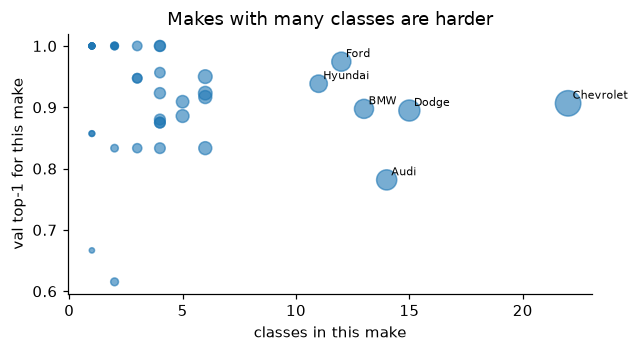

In [6]:
per_make = pred.groupby("true_make").agg(n=("correct", "size"), acc=("correct", "mean"))
per_make["classes"] = pd.Series(make_of_label).value_counts()
per_make = per_make.sort_values("acc")
fig, ax = plt.subplots(figsize=(6, 3.3))
ax.scatter(per_make.classes, per_make.acc, s=per_make.n * 2, alpha=0.6)
for mk, r in per_make[per_make.classes >= 10].iterrows():
    ax.annotate(mk, (r.classes, r.acc), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="classes in this make", ylabel="val top-1 for this make",
       title="Makes with many classes are harder")
fig.tight_layout(); fig.savefig(FIG_DIR / "per_make_accuracy.png")
print(per_make.head(8).round(3).to_string())

In [7]:
per_class = pred.groupby("true_name").correct.mean().sort_values()
print("worst classes on val (val has only 4 to 10 images per class, so these are noisy):")
print(per_class.head(8).round(2).to_string())

worst classes on val (val has only 4 to 10 images per class, so these are noisy):
true_name
Audi V8 Sedan 1994            0.29
Dodge Caliber Wagon 2012      0.33
Chevrolet Express Van 2007    0.40
Acura RL Sedan 2012           0.40
BMW M6 Convertible 2010       0.50
Audi 100 Wagon 1994           0.50
GMC Yukon Hybrid SUV 2012     0.50
Audi TTS Coupe 2012           0.50


### Gallery of the most confident mistakes
Confident mistakes are the dangerous ones, because a threshold cannot catch them. Left: the val image
(bbox crop). Right: a training image of the class the model predicted.

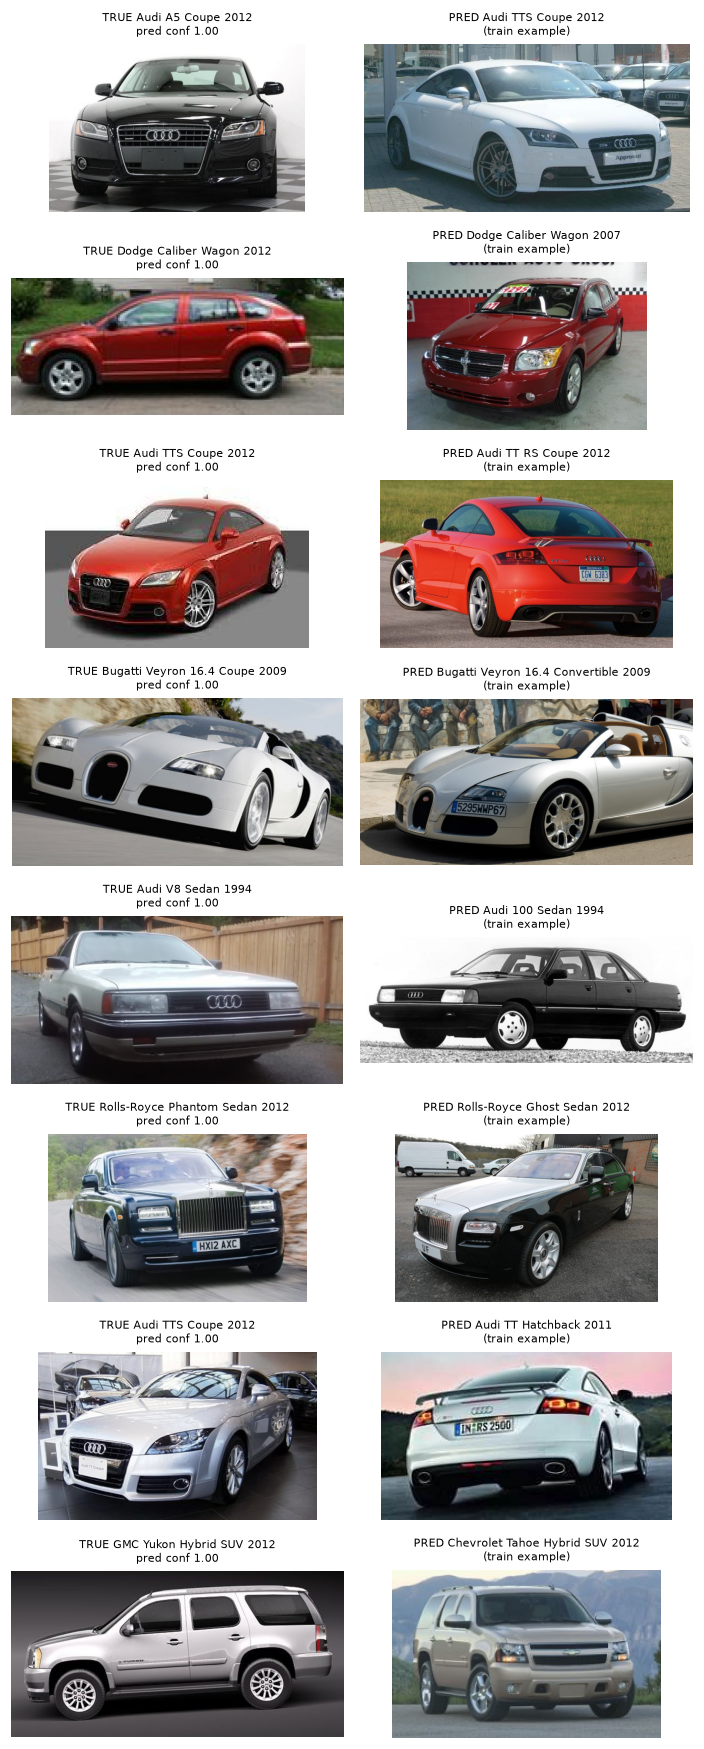

In [8]:
def show_crop(ax, row_df, title):
    img = Image.open(C.IMAGE_ROOT / row_df.path).convert("RGB")
    ax.imshow(crop_box(img, row_df)); ax.set_title(title, fontsize=7); ax.axis("off")

worst = err.sort_values("confidence", ascending=False).head(8)
fig, axes = plt.subplots(len(worst), 2, figsize=(6.5, 2.0 * len(worst)))
for (ax_l, ax_r), (_, r) in zip(axes, worst.iterrows()):
    v = val[val.path == r.path].iloc[0]
    show_crop(ax_l, v, f"TRUE {r.true_name}\npred conf {r.confidence:.2f}")
    t = train[train.label == r.pred].iloc[0]
    show_crop(ax_r, t, f"PRED {r.pred_name}\n(train example)")
fig.tight_layout(); fig.savefig(FIG_DIR / "gallery_confident_mistakes.png")

## 2. (7b) Confidence threshold

The model always outputs a probability over the 196 known classes. Its top probability ("confidence") is
our signal: if it is below a threshold `t`, we answer "unknown" and send the image to a person instead
of guessing. Raising `t` rejects more images (lower **coverage**) but the accepted ones are more often
right (higher **accepted accuracy**). This is the same trade-off as an inspection station that passes,
fails, or sends a part to manual review.

In [9]:
def sweep_thresholds(probs, labels, ts=np.round(np.arange(0, 1.0, 0.01), 2)):
    conf, correct = probs.max(1), probs.argmax(1) == labels
    rows = []
    for t in ts:
        keep = conf >= t
        rows.append({"threshold": t, "coverage": keep.mean(), "rejected": 1 - keep.mean(),
                     "accepted_top1": correct[keep].mean() if keep.any() else np.nan,
                     "wrong_accepted_share": (~correct & keep).mean(),
                     "correct_rejected_share": (correct & ~keep).mean()})
    return pd.DataFrame(rows)


def ece(probs, labels, bins=15):
    """Expected calibration error: average gap between confidence and accuracy."""
    conf, correct = probs.max(1), probs.argmax(1) == labels
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(conf, edges) - 1, 0, bins - 1)
    return sum(np.abs(conf[idx == b].mean() - correct[idx == b].mean()) * (idx == b).mean()
               for b in range(bins) if (idx == b).any())


TARGET_ACCEPTED_ACC = 0.95  # the operating rule, fixed before looking at the curve (see decisions.md)

def choose_threshold(sw):
    ok = sw[sw.accepted_top1 >= TARGET_ACCEPTED_ACC]
    return float(ok.threshold.min())


def bootstrap_at(probs, labels, t, n=2000, seed=C.SEED):
    rng = np.random.default_rng(seed)
    conf, correct = probs.max(1), probs.argmax(1) == labels
    covs, accs = [], []
    for _ in range(n):
        i = rng.integers(0, len(labels), len(labels))
        k = conf[i] >= t
        covs.append(k.mean()); accs.append(correct[i][k].mean())
    return np.percentile(covs, [2.5, 97.5]), np.percentile(accs, [2.5, 97.5])

In [10]:
probs_best = np.load(OUT / BEST_RUN / "probs_val.npy").astype(np.float32)
labels_val = val.label.values
sw = sweep_thresholds(probs_best, labels_val)
sw.to_csv(OUT / BEST_RUN / "threshold_sweep_val.csv", index=False)
t_best = choose_threshold(sw)
r = sw[sw.threshold == t_best].iloc[0]
cov_ci, acc_ci = bootstrap_at(probs_best, labels_val, t_best)
print(f"{BEST_RUN}: ECE {ece(probs_best, labels_val):.3f}")
print(f"chosen t = {t_best:.2f}: coverage {r.coverage:.1%} (95% CI {cov_ci[0]:.1%} to {cov_ci[1]:.1%}), "
      f"accepted top-1 {r.accepted_top1:.1%} (95% CI {acc_ci[0]:.1%} to {acc_ci[1]:.1%})")
print(sw[sw.threshold.isin([0, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95])].round(3).to_string(index=False))

ft_crop: ECE 0.039
chosen t = 0.75: coverage 90.0% (95% CI 88.3% to 91.7%), accepted top-1 95.0% (95% CI 93.6% to 96.2%)
 threshold  coverage  rejected  accepted_top1  wrong_accepted_share  correct_rejected_share
      0.00     1.000     0.000          0.911                 0.089                   0.000
      0.30     0.997     0.003          0.913                 0.087                   0.001
      0.50     0.969     0.031          0.927                 0.071                   0.013
      0.70     0.918     0.082          0.945                 0.051                   0.043
      0.80     0.877     0.123          0.957                 0.038                   0.071
      0.90     0.824     0.176          0.964                 0.029                   0.116
      0.95     0.773     0.227          0.969                 0.024                   0.162


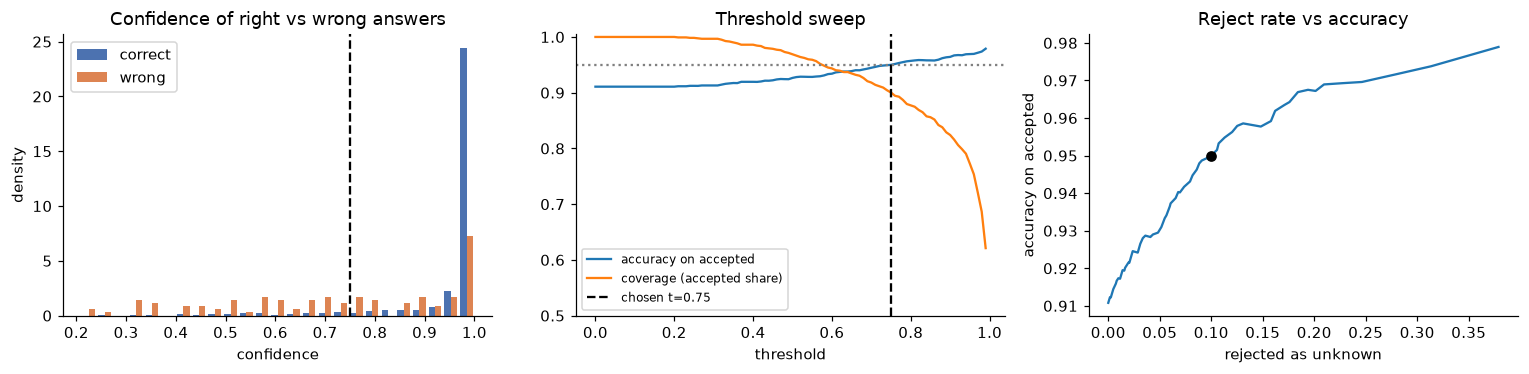

In [11]:
conf = probs_best.max(1); correct = probs_best.argmax(1) == labels_val
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist([conf[correct], conf[~correct]], bins=25, label=["correct", "wrong"], color=["#4c72b0", "#dd8452"],
             stacked=False, density=True)
axes[0].axvline(t_best, color="k", ls="--"); axes[0].set(xlabel="confidence", ylabel="density",
                                                         title="Confidence of right vs wrong answers")
axes[0].legend()
axes[1].plot(sw.threshold, sw.accepted_top1, label="accuracy on accepted")
axes[1].plot(sw.threshold, sw.coverage, label="coverage (accepted share)")
axes[1].axvline(t_best, color="k", ls="--", label=f"chosen t={t_best:.2f}")
axes[1].axhline(TARGET_ACCEPTED_ACC, color="gray", ls=":")
axes[1].set(xlabel="threshold", ylim=(0.5, 1.005), title="Threshold sweep"); axes[1].legend(fontsize=8)
axes[2].plot(sw.rejected, sw.accepted_top1)
axes[2].scatter([r.rejected], [r.accepted_top1], color="k", zorder=3)
axes[2].set(xlabel="rejected as unknown", ylabel="accuracy on accepted", title="Reject rate vs accuracy")
fig.tight_layout(); fig.savefig(FIG_DIR / "threshold_sweep.png")

### Reliability check
If the model is well calibrated, images with confidence 0.8 are right about 80% of the time. If it is
overconfident, the curve sits below the diagonal, and a threshold of 0.8 means less than it says.

      conf    acc     n
bin                    
2    0.241  0.250     4
3    0.342  0.308    13
4    0.454  0.524    21
5    0.553  0.645    31
6    0.658  0.548    31
7    0.753  0.680    50
8    0.855  0.846    65
9    0.990  0.964  1007


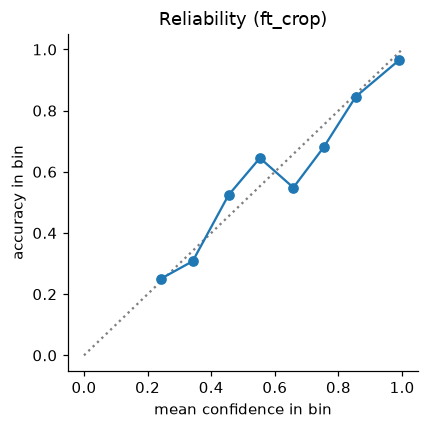

In [12]:
edges = np.linspace(0, 1, 11)
idx = np.clip(np.digitize(conf, edges) - 1, 0, 9)
rel = pd.DataFrame({"bin": idx, "conf": conf, "correct": correct}).groupby("bin").agg(
    conf=("conf", "mean"), acc=("correct", "mean"), n=("correct", "size"))
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot([0, 1], [0, 1], ":", color="gray")
ax.plot(rel.conf, rel.acc, "o-")
ax.set(xlabel="mean confidence in bin", ylabel="accuracy in bin", title=f"Reliability ({BEST_RUN})")
fig.tight_layout(); fig.savefig(FIG_DIR / "reliability.png")
print(rel.round(3).to_string())

## 3. (7c) Robustness: low resolution, blur, darkness

Each val image goes through the normal pipeline (crop, resize to 224) and is then degraded:
- **resolution**: shrink to 112, 64, or 32 px and scale back to 224 (a far-away car or a cheap camera)
- **blur**: Gaussian blur with sigma 1 to 4 px (motion, focus)
- **dark**: brightness multiplied by 0.5, 0.3, 0.15 (dusk, night)

Then the same thing for a model retrained with random degradation augmentation (`<best>_degaug`).

run                   ft_crop  ft_crop_degaug
family     condition                         
resolution res224       0.911           0.905
           res112       0.757           0.903
           res64        0.371           0.868
           res32        0.043           0.703
blur       blur0        0.911           0.905
           blur1        0.836           0.899
           blur2        0.448           0.879
           blur3        0.169           0.813
           blur4        0.065           0.733
dark       dark1.0      0.911           0.905
           dark0.5      0.894           0.908
           dark0.3      0.886           0.904
           dark0.15     0.845           0.894


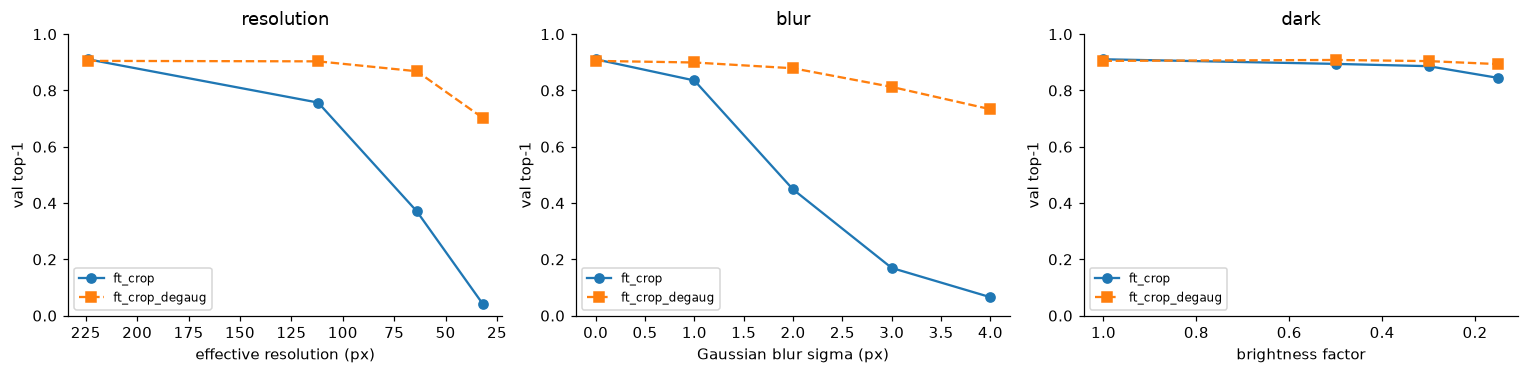

In [13]:
DEG_RUN = f"{BEST_RUN}_degaug"
deg = pd.concat([evaluate_degradations(BEST_RUN, "val"), evaluate_degradations(DEG_RUN, "val")])
deg.to_csv(OUT / "degradation_val_comparison.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (family, xlabel) in zip(axes, [("resolution", "effective resolution (px)"),
                                       ("blur", "Gaussian blur sigma (px)"), ("dark", "brightness factor")]):
    for run, style in [(BEST_RUN, "o-"), (DEG_RUN, "s--")]:
        d = deg[(deg.run == run) & (deg.family == family)]
        ax.plot(d.level, d.top1, style, label=run)
    ax.set(xlabel=xlabel, ylabel="val top-1", ylim=(0, 1), title=family)
    if family in ("resolution", "dark"):
        ax.invert_xaxis()
    ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "degradation_val.png")
print(deg.pivot_table(index=["family", "condition"], columns="run", values="top1", sort=False).round(3).to_string())

## 4. Final choice (val only)

Rule, written down before the degradation results (see decisions.md): use the degradation-augmented model
as the final model if its clean val top-1 is within 1.0 point of the original and it is better on average
over the degraded conditions. Otherwise keep the original. The threshold is then re-derived for the
chosen model with the same 95% accepted-accuracy rule.

In [14]:
pivot = deg.pivot_table(index="condition", columns="run", values="top1")
clean_drop = pivot.loc["res224", BEST_RUN] - pivot.loc["res224", DEG_RUN]
degraded = pivot.drop(index=["res224", "blur0", "dark1.0"])
avg_gain = (degraded[DEG_RUN] - degraded[BEST_RUN]).mean()
FINAL_RUN = DEG_RUN if (clean_drop <= 0.010 and avg_gain > 0) else BEST_RUN
print(f"clean val top-1 change with degradation aug: {-clean_drop * 100:+.1f} points")
print(f"average change over degraded conditions: {avg_gain * 100:+.1f} points")
print("FINAL_RUN:", FINAL_RUN)

probs_final = np.load(OUT / FINAL_RUN / "probs_val.npy").astype(np.float32)
sw_final = sweep_thresholds(probs_final, labels_val)
sw_final.to_csv(OUT / FINAL_RUN / "threshold_sweep_val.csv", index=False)
t_final = choose_threshold(sw_final)
rf = sw_final[sw_final.threshold == t_final].iloc[0]
cov_ci, acc_ci = bootstrap_at(probs_final, labels_val, t_final)
print(f"threshold for {FINAL_RUN}: {t_final:.2f}  coverage {rf.coverage:.1%} "
      f"(95% CI {cov_ci[0]:.1%} to {cov_ci[1]:.1%})  accepted top-1 {rf.accepted_top1:.1%} "
      f"(95% CI {acc_ci[0]:.1%} to {acc_ci[1]:.1%})  ECE {ece(probs_final, labels_val):.3f}")

choice = {"final_run": FINAL_RUN, "threshold": t_final, "rule": f"lowest t with val accepted top-1 >= {TARGET_ACCEPTED_ACC}",
          "val_top1": float(pivot.loc["res224", FINAL_RUN]), "val_coverage": float(rf.coverage),
          "val_accepted_top1": float(rf.accepted_top1)}
(OUT / "final_choice.json").write_text(json.dumps(choice, indent=2))
choice

clean val top-1 change with degradation aug: -0.6 points
average change over degraded conditions: +31.9 points
FINAL_RUN: ft_crop_degaug
threshold for ft_crop_degaug: 0.76  coverage 87.6% (95% CI 85.7% to 89.4%)  accepted top-1 95.1% (95% CI 93.8% to 96.3%)  ECE 0.035


{'final_run': 'ft_crop_degaug',
 'threshold': 0.76,
 'rule': 'lowest t with val accepted top-1 >= 0.95',
 'val_top1': 0.9050736497545008,
 'val_coverage': 0.8756137479541735,
 'val_accepted_top1': 0.9514018691588785}

In [15]:
deg_thr = evaluate_degradations(FINAL_RUN, "val", threshold=t_final)
print("With the threshold on degraded val images: does the model know when it does not know?")
print(deg_thr[["family", "condition", "top1", "coverage", "accepted_top1"]].round(3).to_string(index=False))

With the threshold on degraded val images: does the model know when it does not know?
    family condition  top1  coverage  accepted_top1
resolution    res224 0.905     0.876          0.951
resolution    res112 0.903     0.879          0.946
resolution     res64 0.868     0.836          0.932
resolution     res32 0.703     0.595          0.884
      blur     blur0 0.905     0.876          0.951
      blur     blur1 0.899     0.880          0.947
      blur     blur2 0.879     0.854          0.940
      blur     blur3 0.813     0.779          0.926
      blur     blur4 0.733     0.666          0.892
      dark   dark1.0 0.905     0.876          0.951
      dark   dark0.5 0.908     0.888          0.952
      dark   dark0.3 0.904     0.887          0.952
      dark  dark0.15 0.894     0.872          0.953
